In [2]:
print("Hello, World!")

Hello, World!


In [3]:
# Try latin-1 first (most common fix for these files)
upc = pd.read_csv(DATA_DIR / "upccer.csv", encoding="latin-1")
print("UPC shape:", upc.shape)
print(upc.columns.tolist())
upc.head()

NameError: name 'pd' is not defined

In [4]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")

# Load UPC descriptions
# Try latin-1 first (most common fix for these files)
upc = pd.read_csv(DATA_DIR / "upccer.csv", encoding="latin-1")
print("UPC shape:", upc.shape)
print(upc.columns.tolist())
upc.head()

# upc = pd.read_csv(DATA_DIR / "upccer.csv")
# print("UPC shape:", upc.shape)
# print(upc.columns.tolist())
# display(upc.head())


# Load movement (weekly sales/prices)
move = pd.read_csv(DATA_DIR / "wcer.csv")
print("\nMovement shape:", move.shape)
print(move.columns.tolist())
display(move.head())

UPC shape: (490, 6)
['COM_CODE', 'UPC', 'DESCRIP', 'SIZE', 'CASE', 'NITEM']

Movement shape: (6602582, 11)
['STORE', 'UPC', 'WEEK', 'MOVE', 'QTY', 'PRICE', 'SALE', 'PROFIT', 'OK', 'PRICE_HEX', 'PROFIT_HEX']


,STORE,UPC,WEEK,MOVE,QTY,PRICE,SALE,PROFIT,OK,PRICE_HEX,PROFIT_HEX
0,51,317,372,1,1,26.02,NaN,62.52,1,403A051EB851EB85,404F428F5C28F5C3
1,51,317,373,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000
2,51,317,374,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000
3,51,317,375,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000
4,51,317,376,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000


In [5]:
# Keep valid observations
move_clean = move[move["OK"] == 1].copy()

# Create unit price and quantity
move_clean["unit_price"] = move_clean["PRICE"] / move_clean["QTY"]
move_clean["units"] = move_clean["MOVE"]

# Merge with product info
df = move_clean.merge(upc, on="UPC", how="left")
print("Merged shape:", df.shape)
df.head()

Merged shape: (6461297, 18)


,STORE,UPC,WEEK,MOVE,QTY,PRICE,SALE,PROFIT,OK,PRICE_HEX,PROFIT_HEX,unit_price,units,COM_CODE,DESCRIP,SIZE,CASE,NITEM
0,51,317,372,1,1,26.02,NaN,62.52,1,403A051EB851EB85,404F428F5C28F5C3,26.02,1,311,$TONY THE TIGER T-SH,ASST,1,9900090
1,51,317,373,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000,0.00,0,311,$TONY THE TIGER T-SH,ASST,1,9900090
2,51,317,374,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000,0.00,0,311,$TONY THE TIGER T-SH,ASST,1,9900090
3,51,317,375,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000,0.00,0,311,$TONY THE TIGER T-SH,ASST,1,9900090
4,51,317,376,0,1,0.00,NaN,0.00,1,0000000000000000,0000000000000000,0.00,0,311,$TONY THE TIGER T-SH,ASST,1,9900090


In [ ]:
# Overview of the merged dataset
print(f"Merged shape: {df.shape}")
print(f"Unique UPCs: {df['UPC'].nunique():,}")
print(f"Unique stores: {df['STORE'].nunique():,}")
print(f"Weeks: {df['WEEK'].min()} – {df['WEEK'].max()}")
print(f"Columns: {df.columns.tolist()}")

Merged shape: (6461297, 18)
Unique UPCs: 490
Unique stores: 93
Weeks: 1 – 399
Columns: ['STORE', 'UPC', 'WEEK', 'MOVE', 'QTY', 'PRICE', 'SALE', 'PROFIT', 'OK', 'PRICE_HEX', 'PROFIT_HEX', 'unit_price', 'units', 'COM_CODE', 'DESCRIP', 'SIZE', 'CASE', 'NITEM']


In [8]:
# Top Products by units sold
top_products = (
    df.groupby(["UPC", "DESCRIP"])["units"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)
display(top_products)

,UPC,DESCRIP,units
0,1600066610,CHEERIOS,2011819
1,3800000120,KELLOGGS CORN FLAKES,1830189
2,1600066510,CHEERIOS,1560241
3,1600066590,HONEY NUT CHEERIOS,1512370
4,3800001520,KELLOGG'S FROSTED FL,1322703
5,3800001510,KELLOGG'S FROSTED FL,1287272
6,3800001720,KELLOGGS FRUIT LOOPS,1208611
7,3800000110,KELLOGGS CORN FLAKES,1167781
8,3800001611,KELLOGGS SPECIAL K,1077255
9,3800000520,KELLOGGS RICE KRISPI,1063040


In [9]:
# Basic Price and Volumne Stats
print(df[["unit_price", "units", "PRICE", "PROFIT"]].describe())

         unit_price         units         PRICE        PROFIT
count  6.461297e+06  6.461297e+06  6.461297e+06  6.461297e+06
mean   2.270148e+00  1.404779e+01  2.271354e+00  1.269162e+01
std    1.531765e+00  3.832573e+01  1.532149e+00  1.144144e+01
min    0.000000e+00  0.000000e+00  0.000000e+00 -9.969000e+01
25%    0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
50%    2.790000e+00  8.000000e+00  2.790000e+00  1.398000e+01
75%    3.390000e+00  1.700000e+01  3.390000e+00  1.873000e+01
max    2.602000e+01  1.782400e+04  2.602000e+01  9.999000e+01


In [10]:
# Drop rows with zero price or zero units
df_clean = df[(df["unit_price"] > 0) & (df["units"] > 0)].copy()
print(f"Rows after cleaning: {len(df_clean):,}")
print(df_clean[["unit_price", "units"]].describe())

Rows after cleaning: 4,707,776
         unit_price         units
count  4.707776e+06  4.707776e+06
mean   3.115717e+00  1.928022e+01
std    7.652992e-01  4.376176e+01
min    5.000000e-02  1.000000e+00
25%    2.650000e+00  7.000000e+00
50%    3.150000e+00  1.300000e+01
75%    3.590000e+00  2.100000e+01
max    2.602000e+01  1.782400e+04


In [14]:
# Weekly totals across all stores
weekly = (
    df_clean.groupby("WEEK")
    .agg(
        total_units=("units", "sum"),
        avg_price=("unit_price", "mean"),
        median_price=("unit_price", "median"),
        n_upcs=("UPC", "nunique"),
        n_stores=("STORE", "nunique"),
    )
    .reset_index()
    .sort_values("WEEK")
)
print(weekly.shape)
display(weekly.head(8))
display(weekly.tail(5))

(366, 6)


,WEEK,total_units,avg_price,median_price,n_upcs,n_stores
0,1,212198,2.606195,2.62,179,71
1,2,210969,2.603836,2.63,180,69
2,3,270231,2.605125,2.63,180,71
3,4,209547,2.623235,2.65,183,73
4,5,209558,2.623959,2.63,185,73
5,6,182175,2.623690,2.63,185,68
6,7,206763,2.635040,2.63,185,68
7,8,222253,2.630960,2.63,184,72


,WEEK,total_units,avg_price,median_price,n_upcs,n_stores
361,395,249587,3.152996,3.19,202,83
362,396,297000,3.182525,3.19,203,83
363,397,343254,3.157225,3.19,203,83
364,398,344690,3.174431,3.19,202,83
365,399,259369,3.123565,3.18,200,83


In [15]:
# Top Products
top_mixed = (
    df_clean.groupby(["UPC", "DESCRIP"])["units"]
    .sum()
    .sort_values(ascending=False)
    .head(12)
    .reset_index()
)
display(top_mixed)

,UPC,DESCRIP,units
0,1600066610,CHEERIOS,2011819
1,3800000120,KELLOGGS CORN FLAKES,1830189
2,1600066510,CHEERIOS,1560241
3,1600066590,HONEY NUT CHEERIOS,1512370
4,3800001520,KELLOGG'S FROSTED FL,1322703
5,3800001510,KELLOGG'S FROSTED FL,1287272
6,3800001720,KELLOGGS FRUIT LOOPS,1208611
7,3800000110,KELLOGGS CORN FLAKES,1167781
8,3800001611,KELLOGGS SPECIAL K,1077255
9,3800000520,KELLOGGS RICE KRISPI,1063040


In [ ]:
# simple time series holdout + price-volume view
# Create a clean weekly series and mark the holdout
# Last 8 weeks as holdout (you can change this)
HOLDOUT_WEEKS = 8
max_week = weekly["WEEK"].max()
train_weeks = weekly[weekly["WEEK"] <= max_week - HOLDOUT_WEEKS].copy()
holdout_weeks = weekly[weekly["WEEK"] > max_week - HOLDOUT_WEEKS].copy()

print(f"Train weeks: {train_weeks['WEEK'].min()} – {train_weeks['WEEK'].max()}  ({len(train_weeks)} weeks)")
print(f"Holdout weeks: {holdout_weeks['WEEK'].min()} – {holdout_weeks['WEEK'].max()}  ({len(holdout_weeks)} weeks)")

Train weeks: 1 – 391  (358 weeks)
Holdout weeks: 392 – 399  (8 weeks)


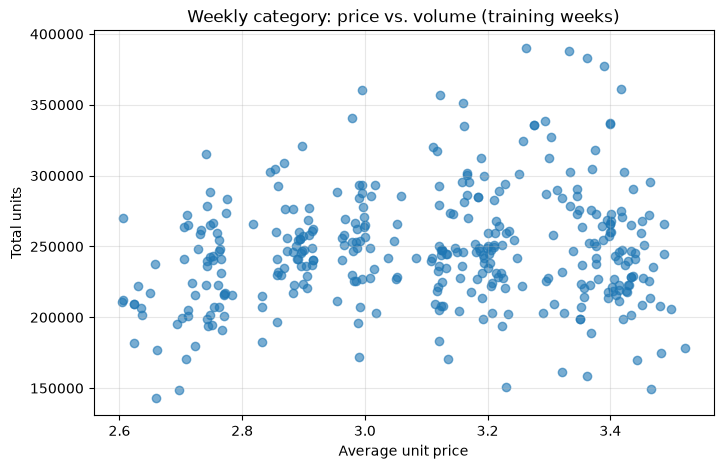

In [17]:
#  2. Quick price vs. volume scatter (training period)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(train_weeks["avg_price"], train_weeks["total_units"], alpha=0.6)
plt.xlabel("Average unit price")
plt.ylabel("Total units")
plt.title("Weekly category: price vs. volume (training weeks)")
plt.grid(True, alpha=0.3)
plt.show()

In [18]:
# 3. Simple baseline: last-train-week volume as forecast
last_train_units = train_weeks["total_units"].iloc[-1]
holdout_weeks = holdout_weeks.copy()
holdout_weeks["naive_forecast"] = last_train_units
holdout_weeks["error"] = holdout_weeks["total_units"] - holdout_weeks["naive_forecast"]

print("Naive forecast (last train week units):", last_train_units)
display(holdout_weeks[["WEEK", "total_units", "naive_forecast", "error", "avg_price"]])

Naive forecast (last train week units): 231323


,WEEK,total_units,naive_forecast,error,avg_price
358,392,266090,231323,34767,3.188336
359,393,250588,231323,19265,3.160984
360,394,250588,231323,19265,3.160984
361,395,249587,231323,18264,3.152996
362,396,297000,231323,65677,3.182525
363,397,343254,231323,111931,3.157225
364,398,344690,231323,113367,3.174431
365,399,259369,231323,28046,3.123565


In [19]:
# BETTER BASELINES
# 1. Mean of the last 4 training weeks
last4_mean = train_weeks["total_units"].tail(4).mean()
holdout_weeks["mean4_forecast"] = last4_mean
holdout_weeks["mean4_error"] = holdout_weeks["total_units"] - holdout_weeks["mean4_forecast"]

print(f"Mean of last 4 train weeks: {last4_mean:,.0f}")
display(holdout_weeks[["WEEK", "total_units", "naive_forecast", "mean4_forecast", "mean4_error", "avg_price"]])

Mean of last 4 train weeks: 247,605


,WEEK,total_units,naive_forecast,mean4_forecast,mean4_error,avg_price
358,392,266090,231323,247605.25,18484.75,3.188336
359,393,250588,231323,247605.25,2982.75,3.160984
360,394,250588,231323,247605.25,2982.75,3.160984
361,395,249587,231323,247605.25,1981.75,3.152996
362,396,297000,231323,247605.25,49394.75,3.182525
363,397,343254,231323,247605.25,95648.75,3.157225
364,398,344690,231323,247605.25,97084.75,3.174431
365,399,259369,231323,247605.25,11763.75,3.123565


In [20]:
# 2. Simple linear trend on training weeks
from sklearn.linear_model import LinearRegression

X_train = train_weeks[["WEEK"]]
y_train = train_weeks["total_units"]

trend_model = LinearRegression().fit(X_train, y_train)
holdout_weeks["trend_forecast"] = trend_model.predict(holdout_weeks[["WEEK"]])
holdout_weeks["trend_error"] = holdout_weeks["total_units"] - holdout_weeks["trend_forecast"]

print(f"Trend slope (units per week): {trend_model.coef_[0]:,.1f}")
display(holdout_weeks[["WEEK", "total_units", "trend_forecast", "trend_error"]])

Trend slope (units per week): 60.8


,WEEK,total_units,trend_forecast,trend_error
358,392,266090,259687.863976,6402.136024
359,393,250588,259748.641665,-9160.641665
360,394,250588,259809.419355,-9221.419355
361,395,249587,259870.197045,-10283.197045
362,396,297000,259930.974734,37069.025266
363,397,343254,259991.752424,83262.247576
364,398,344690,260052.530113,84637.469887
365,399,259369,260113.307803,-744.307803


In [21]:
# 3. Compare the three forecasts
comparison = holdout_weeks[["WEEK", "total_units", "naive_forecast", "mean4_forecast", "trend_forecast"]].copy()
comparison["naive_abs_err"] = (comparison["total_units"] - comparison["naive_forecast"]).abs()
comparison["mean4_abs_err"] = (comparison["total_units"] - comparison["mean4_forecast"]).abs()
comparison["trend_abs_err"] = (comparison["total_units"] - comparison["trend_forecast"]).abs()

print("Mean absolute error:")
print(f"  Naive:  {comparison['naive_abs_err'].mean():,.0f}")
print(f"  Mean-4: {comparison['mean4_abs_err'].mean():,.0f}")
print(f"  Trend:  {comparison['trend_abs_err'].mean():,.0f}")
display(comparison)

Mean absolute error:
  Naive:  51,323
  Mean-4: 35,040
  Trend:  30,098


,WEEK,total_units,naive_forecast,mean4_forecast,trend_forecast,naive_abs_err,mean4_abs_err,trend_abs_err
358,392,266090,231323,247605.25,259687.863976,34767,18484.75,6402.136024
359,393,250588,231323,247605.25,259748.641665,19265,2982.75,9160.641665
360,394,250588,231323,247605.25,259809.419355,19265,2982.75,9221.419355
361,395,249587,231323,247605.25,259870.197045,18264,1981.75,10283.197045
362,396,297000,231323,247605.25,259930.974734,65677,49394.75,37069.025266
363,397,343254,231323,247605.25,259991.752424,111931,95648.75,83262.247576
364,398,344690,231323,247605.25,260052.530113,113367,97084.75,84637.469887
365,399,259369,231323,247605.25,260113.307803,28046,11763.75,744.307803


In [22]:
# Add price as a feature
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Training features: week + average price
X_train = train_weeks[["WEEK", "avg_price"]]
y_train = train_weeks["total_units"]

price_model = LinearRegression().fit(X_train, y_train)

# Forecast holdout
X_hold = holdout_weeks[["WEEK", "avg_price"]]
holdout_weeks["price_forecast"] = price_model.predict(X_hold)
holdout_weeks["price_error"] = holdout_weeks["total_units"] - holdout_weeks["price_forecast"]

print("Coefficients:")
print(f"  Week (trend):  {price_model.coef_[0]:,.1f} units per week")
print(f"  Avg price:     {price_model.coef_[1]:,.1f} units per $1")
print(f"  Intercept:     {price_model.intercept_:,.0f}")

print("\nMean absolute error:")
print(f"  Trend only:    {comparison['trend_abs_err'].mean():,.0f}")
print(f"  Trend + price: {holdout_weeks['price_error'].abs().mean():,.0f}")

display(holdout_weeks[["WEEK", "total_units", "trend_forecast", "price_forecast", "avg_price"]])

Coefficients:
  Week (trend):  61.9 units per week
  Avg price:     -586.0 units per $1
  Intercept:     237,474

Mean absolute error:
  Trend only:    30,098
  Trend + price: 30,105


,WEEK,total_units,trend_forecast,price_forecast,avg_price
358,392,266090,259687.863976,259865.422676,3.188336
359,393,250588,259748.641665,259943.339186,3.160984
360,394,250588,259809.419355,260005.226393,3.160984
361,395,249587,259870.197045,260071.794628,3.152996
362,396,297000,259930.974734,260116.376685,3.182525
363,397,343254,259991.752424,260193.090529,3.157225
364,398,344690,260052.530113,260244.894435,3.174431
365,399,259369,260113.307803,260336.590771,3.123565


In [ ]:
# Product-level price response
# One UPC (change this if you prefer another)
TARGET_UPC = 3800000120   # Kellogg's Corn Flakes

product = df_clean[df_clean["UPC"] == TARGET_UPC].copy()
print(f"Rows for UPC {TARGET_UPC}: {len(product):,}")
print(product["DESCRIP"].iloc[0])

# Weekly aggregation for this product
prod_weekly = (
    product.groupby("WEEK")
    .agg(
        total_units=("units", "sum"),
        avg_price=("unit_price", "mean"),
        n_stores=("STORE", "nunique"),
    )
    .reset_index()
    .sort_values("WEEK")
)
print(prod_weekly.shape)
display(prod_weekly.head())

In [1]:
# 2. Train / holdout split
HOLDOUT_WEEKS = 8
max_week = prod_weekly["WEEK"].max()
train = prod_weekly[prod_weekly["WEEK"] <= max_week - HOLDOUT_WEEKS].copy()
hold = prod_weekly[prod_weekly["WEEK"] > max_week - HOLDOUT_WEEKS].copy()

print(f"Train: {train['WEEK'].min()}–{train['WEEK'].max()} ({len(train)} weeks)")
print(f"Holdout: {hold['WEEK'].min()}–{hold['WEEK'].max()} ({len(hold)} weeks)")

NameError: name 'prod_weekly' is not defined

In [ ]:
# 3. Trend-only vs. trend + price
from sklearn.linear_model import LinearRegression

# Trend only
trend = LinearRegression().fit(train[["WEEK"]], train["total_units"])
hold["trend_forecast"] = trend.predict(hold[["WEEK"]])

# Trend + price
price_model = LinearRegression().fit(train[["WEEK", "avg_price"]], train["total_units"])
hold["price_forecast"] = price_model.predict(hold[["WEEK", "avg_price"]])

print("Coefficients (trend + price model):")
print(f"  Week:      {price_model.coef_[0]:,.1f} units/week")
print(f"  Avg price: {price_model.coef_[1]:,.1f} units per $1")

# Errors
hold["trend_abs_err"] = (hold["total_units"] - hold["trend_forecast"]).abs()
hold["price_abs_err"] = (hold["total_units"] - hold["price_forecast"]).abs()

print("\nMean absolute error:")
print(f"  Trend only:    {hold['trend_abs_err'].mean():,.0f}")
print(f"  Trend + price: {hold['price_abs_err'].mean():,.0f}")

display(hold[["WEEK", "total_units", "avg_price", "trend_forecast", "price_forecast"]])

In [6]:
# PRICING FOR ONE PRODUCT
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# --- Load and clean data ---
DATA_DIR = Path("data")

upc = pd.read_csv(DATA_DIR / "upccer.csv", encoding="latin-1")
move = pd.read_csv(DATA_DIR / "wcer.csv")

move_clean = move[move["OK"] == 1].copy()
move_clean["unit_price"] = move_clean["PRICE"] / move_clean["QTY"]
move_clean["units"] = move_clean["MOVE"]

df = move_clean.merge(upc, on="UPC", how="left")
df_clean = df[(df["unit_price"] > 0) & (df["units"] > 0)].copy()
print(f"Clean rows: {len(df_clean):,}")

# --- Product-level weekly data ---
TARGET_UPC = 3800000120   # Kellogg's Corn Flakes

product = df_clean[df_clean["UPC"] == TARGET_UPC].copy()
print(f"Product: {product['DESCRIP'].iloc[0]}")

prod_weekly = (
    product.groupby("WEEK")
    .agg(
        total_units=("units", "sum"),
        avg_price=("unit_price", "mean"),
    )
    .reset_index()
    .sort_values("WEEK")
)

# Train / holdout
HOLDOUT_WEEKS = 8
max_week = prod_weekly["WEEK"].max()
train = prod_weekly[prod_weekly["WEEK"] <= max_week - HOLDOUT_WEEKS].copy()
hold = prod_weekly[prod_weekly["WEEK"] > max_week - HOLDOUT_WEEKS].copy()

print(f"Train weeks: {len(train)} | Holdout weeks: {len(hold)}")

# --- Elasticity ---
train_elast = train[(train["avg_price"] > 0) & (train["total_units"] > 0)].copy()
train_elast["log_units"] = np.log(train_elast["total_units"])
train_elast["log_price"] = np.log(train_elast["avg_price"])

elast_model = LinearRegression().fit(
    train_elast[["log_price", "WEEK"]],
    train_elast["log_units"]
)

elasticity = elast_model.coef_[0]
current_price = train["avg_price"].tail(4).mean()

print(f"\nEstimated price elasticity: {elasticity:.2f}")
print(f"Recent average price: ${current_price:.2f}")

if elasticity < -1:
    print("→ Demand is elastic: lowering price should raise revenue")
elif elasticity > -1:
    print("→ Demand is inelastic: raising price should raise revenue")
else:
    print("→ Elasticity near -1: current price is near revenue-maximizing")

Clean rows: 4,707,776
Product: KELLOGGS CORN FLAKES
Train weeks: 358 | Holdout weeks: 8

Estimated price elasticity: -3.70
Recent average price: $2.76
→ Demand is elastic: lowering price should raise revenue


In [7]:
# PRICING STATEGY FOR ONE PRODUCT with Margin
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- settings ----------
TARGET_UPC = 3800000120          # Kellogg's Corn Flakes
PREFERRED_MARGIN = 0.37          # 37% — change this to whatever you want
HOLDOUT_WEEKS = 8
# ------------------------------

# Load & clean
DATA_DIR = Path("data")
upc = pd.read_csv(DATA_DIR / "upccer.csv", encoding="latin-1")
move = pd.read_csv(DATA_DIR / "wcer.csv")

move_clean = move[move["OK"] == 1].copy()
move_clean["unit_price"] = move_clean["PRICE"] / move_clean["QTY"]
move_clean["units"] = move_clean["MOVE"]

df = move_clean.merge(upc, on="UPC", how="left")
df_clean = df[(df["unit_price"] > 0) & (df["units"] > 0)].copy()

# Product weekly series
product = df_clean[df_clean["UPC"] == TARGET_UPC].copy()
print(f"Product: {product['DESCRIP'].iloc[0]}")

prod_weekly = (
    product.groupby("WEEK")
    .agg(total_units=("units", "sum"), avg_price=("unit_price", "mean"))
    .reset_index()
    .sort_values("WEEK")
)

max_week = prod_weekly["WEEK"].max()
train = prod_weekly[prod_weekly["WEEK"] <= max_week - HOLDOUT_WEEKS].copy()

# Elasticity (log-log)
train_elast = train[(train["avg_price"] > 0) & (train["total_units"] > 0)].copy()
train_elast["log_units"] = np.log(train_elast["total_units"])
train_elast["log_price"] = np.log(train_elast["avg_price"])

elast_model = LinearRegression().fit(
    train_elast[["log_price", "WEEK"]], train_elast["log_units"]
)
elasticity = elast_model.coef_[0]

current_price = train["avg_price"].tail(4).mean()
unit_cost = current_price * (1 - PREFERRED_MARGIN)

# Optimal price
if abs(elasticity) > 1:
    optimal_price = unit_cost * abs(elasticity) / (abs(elasticity) - 1)
else:
    optimal_price = np.nan   # formula not valid when |elasticity| ≤ 1

print(f"\nElasticity:          {elasticity:.2f}")
print(f"Recent avg price:    ${current_price:.2f}")
print(f"Implied unit cost:   ${unit_cost:.2f}  (at {PREFERRED_MARGIN:.0%} margin)")
print(f"Recommended price:   ${optimal_price:.2f}" if not np.isnan(optimal_price) else "Recommended price: n/a (elasticity too inelastic)")

Product: KELLOGGS CORN FLAKES

Elasticity:          -3.70
Recent avg price:    $2.76
Implied unit cost:   $1.74  (at 37% margin)
Recommended price:   $2.38
